Malick Sonko Random Forest Model

--- Model Performance ---
Accuracy:  0.7374
Precision: 0.7742
Recall:    0.0554
ROC-AUC:   0.8241


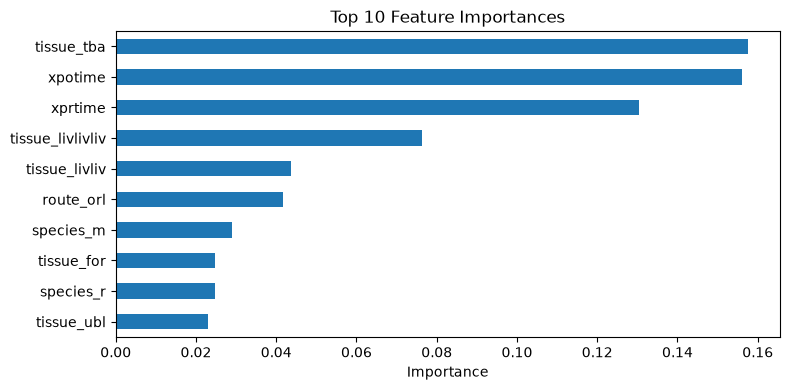

In [1]:
import warnings
warnings.filterwarnings('ignore', category=UserWarning, module='openpyxl')

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score

# Load data
df = pd.read_excel('Carcinogenic Potency Data.xlsx')

# Clean rows missing CAS numbers or targets
df_clean = df.dropna(subset=['cas', 'is_carcinogenic']).copy()
df_clean['cas'] = df_clean['cas'].astype(str)

# Setup features and target
features = ['species', 'sex', 'route', 'tissue', 'xpotime', 'xprtime']
X = pd.get_dummies(df_clean[features], drop_first=True)
y = df_clean['is_carcinogenic'].values
groups = df_clean['cas'].values

# Split by chemical group (80/20)
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

# Fit Random Forest
model = RandomForestClassifier(n_estimators=200, max_depth=15, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)

# Evaluate performance
preds = model.predict(X_test)
probs = model.predict_proba(X_test)[:, 1]

print("--- Model Performance ---")
print(f"Accuracy:  {accuracy_score(y_test, preds):.4f}")
print(f"Precision: {precision_score(y_test, preds):.4f}")
print(f"Recall:    {recall_score(y_test, preds):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, probs):.4f}")

# Plot feature importances
importances = pd.Series(model.feature_importances_, index=X_train.columns).sort_values(ascending=False)
plt.figure(figsize=(8, 4))
importances.head(10).plot(kind='barh', title='Top 10 Feature Importances')
plt.gca().invert_yaxis()
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

In [2]:
import warnings
warnings.filterwarnings('ignore', category=UserWarning, module='openpyxl')

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score

# Load data
df = pd.read_excel('Carcinogenic Potency Data.xlsx')

# Clean rows missing CAS numbers or targets
df_clean = df.dropna(subset=['cas', 'is_carcinogenic']).copy()
df_clean['cas'] = df_clean['cas'].astype(str)

# Setup features and target
features = ['species', 'sex', 'route', 'tissue', 'xpotime', 'xprtime']
X = pd.get_dummies(df_clean[features], drop_first=True)
y = df_clean['is_carcinogenic'].values
groups = df_clean['cas'].values

# Split by chemical group (80/20)
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

# Fit Random Forest
model = RandomForestClassifier(n_estimators=200, max_depth=15, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)

# Evaluate performance
preds = model.predict(X_test)
probs = model.predict_proba(X_test)[:, 1]

# --- EXPORT FILES FOR TEAM GITHUB ---
X_train.to_csv('X_train.csv', index=False)
X_test.to_csv('X_test.csv', index=False)
pd.DataFrame({'is_carcinogenic': y_train}).to_csv('y_train.csv', index=False)
pd.DataFrame({'is_carcinogenic': y_test}).to_csv('y_test.csv', index=False)

pd.DataFrame({
    'y_true': y_test,
    'rf_pred_class': preds,
    'rf_pred_proba': probs
}).to_csv('rf_predictions.csv', index=False)

print("Export complete! CSV files created in your folder.")

Export complete! CSV files created in your folder.
